# Caribu, 2: change a parameter

**What you will learn:** list the parameters with their units, change the plants' leaves, add the sun, change the
leaves' optical properties and the light model, and change the stand's density.

**You need:** tutorial 1. **Run time:** about 30 seconds.

## 1. The parameters

A **parameter** describes the plants (the length of their leaves...) or the light (the latitude, the model...) and
stays fixed during a simulation. `parameters()` lists them all with their value, unit, description and the model
they belong to: `SimplePlant` (the plants' shape), `PlantOptics` (their leaves' optics) or `CaribuLight` (the
light). `parameters(main_only=True)` keeps the main ones.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from openalea.caribu.simulation import parameters, simulate

parameters(main_only=True)

,name,value,unit,description,min_value,max_value,model,main
0,n_leaves,4,adim,The number of leaves,None,None,SimplePlant,True
1,leaf_length,0.2,m,A leaf's length,None,None,SimplePlant,True
2,leaf_width,0.015,m,A leaf's width,None,None,SimplePlant,True
3,leaf_inclination,30.0,°,"A leaf's angle above the horizontal (0: flat, ...",None,None,SimplePlant,True
4,plant_height,0.4,m,"The height of the stem, where the top leaf lea...",None,None,SimplePlant,True
5,leaf_reflectance,0.1,adim,A leaf element's reflectance in the PAR,0.0,1.0,PlantOptics,True
6,leaf_transmittance,0.05,adim,A leaf element's transmittance in the PAR,0.0,1.0,PlantOptics,True
7,mode,direct,,"The light model: 'direct', 'nested' or 'radios...",None,None,CaribuLight,True
8,sun,False,,"The sun with the diffuse sky, its share 1 - th...",None,None,CaribuLight,True
9,latitude,48.85,°,The scene's latitude,None,None,CaribuLight,True


The same parameters in plain words:

| parameter | what it controls | default |
|---|---|---|
| `n_leaves` | number of leaves per plant | 4 |
| `leaf_length`, `leaf_width` | size of a leaf | 20 cm × 1.5 cm |
| `leaf_inclination` | angle of the leaves above the horizontal (0: flat, 90: upright) | 30° |
| `plant_height` | height of the stem, where the top leaf starts | 40 cm |
| `leaf_reflectance` | share of the light hitting a leaf that it reflects | 0.10 |
| `leaf_transmittance` | share that it lets through | 0.05 |
| `mode` | the light model: `direct` (no scattering), `nested` (with scattering) | `direct` |
| `sun` | the sun, besides the diffuse sky | no |
| `latitude` | the site's latitude | 48.85° (Paris) |
| `soil_reflectance` | share of the light reaching the soil that it reflects | 0.15 |

A leaf absorbs what it neither reflects nor transmits: 1 − 0.10 − 0.05 = 85 % by default.

The stand itself (number of rows, spacing) and the time (day, hours) are arguments of `simulate`:
`simulate(rows=3, plants_per_row=8, row_spacing=0.15, plant_spacing=0.05, day_of_year=172, start_hour=0, hours=24)`.

## 2. Change one parameter

`simulate` takes the parameters to change as a dictionary, `{name: value}`. All the others keep their defaults.
Here the leaves are more upright, 70° instead of 30°, at noon under the overcast sky (one hour, faster):

In [2]:
flat = simulate(hours=1, start_hour=12)
upright = simulate({"leaf_inclination": 70.}, hours=1, start_hour=12)
pd.DataFrame({"30°": flat.summary.iloc[0], "70°": upright.summary.iloc[0]}).round(3)

,30°,70°
hour,12.000,12.000
PARi,1749.813,1749.813
PAR_absorbed,1151.293,966.929
absorbed_fraction,0.658,0.553
soil_fraction,0.228,0.352


Upright leaves let more light reach the soil (35 % instead of 23 %): seen from above, they cover less ground. The
canopy absorbs less (55 % instead of 66 %), but its lower leaves get more light, as the drawings show:

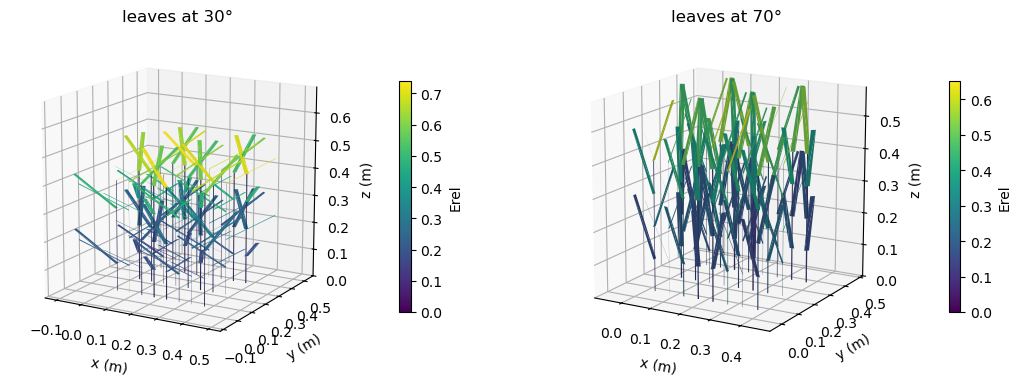

In [3]:
fig = plt.figure(figsize=(13, 5))
for k, (label, result) in enumerate((("leaves at 30°", flat), ("leaves at 70°", upright))):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    result.draw(ax); ax.set_title(label)

## 3. The sun

With `sun=True`, part of the light comes from the sun, from its position at each hour; the rest is diffuse. The
share of diffuse light is estimated from the PAR (Spitters' formula: the less light, the more clouds, the more
diffuse). Upright leaves now behave very differently from flat ones over the day. The hours from 8 to 16 h:

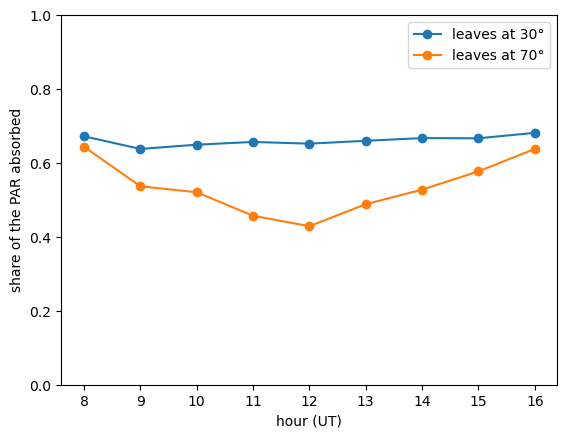

In [4]:
for inclination in (30., 70.):
    sunny = simulate({"sun": True, "leaf_inclination": inclination}, hours=9, start_hour=8)
    plt.plot(sunny.summary["hour"], sunny.summary["absorbed_fraction"], "o-", label=f"leaves at {inclination:.0f}°")
plt.xlabel("hour (UT)"); plt.ylabel("share of the PAR absorbed"); plt.ylim(0, 1); plt.legend();

Flat leaves (30°) absorb about the same share all day. Upright leaves (70°) absorb much less around noon, when the
sun is high and its light slips between them, and more in the morning and evening, when the sun's rays come low,
nearly across the leaves.

**A note on time:** the hours at sunrise and sunset, when the sun is just above the horizon, take much longer to
compute (several seconds each instead of a fraction of a second): the low sun's shadows stretch across many
repetitions of the stand. These tutorials therefore often light the hours from 8 to 16 h.

## 4. The leaves' optical properties, and scattering

The direct model counts only the light that hits a leaf first. Light reflected or transmitted by a leaf is lost:
transmitting more makes the canopy absorb less. The **nested** model also counts the light that leaves scatter onto
other leaves and the light the soil reflects back:

In [5]:
rows = {}
for mode in ("direct", "nested"):
    for transmittance in (0.05, 0.3):
        result = simulate({"mode": mode, "leaf_transmittance": transmittance}, hours=1, start_hour=12)
        rows[f"{mode}, transmittance {transmittance}"] = result.summary.iloc[0][["absorbed_fraction"]]
pd.DataFrame(rows).T.round(3)

,absorbed_fraction
"direct, transmittance 0.05",0.658
"direct, transmittance 0.3",0.473
"nested, transmittance 0.05",0.746
"nested, transmittance 0.3",0.644


With scattering (nested), the canopy absorbs more: the light passed on by a leaf can be absorbed by another. Leaves
that transmit more absorb less themselves, but part of what they let through is recovered by the leaves below. The
direct model ignores this and is fast; the nested model is more exact. In the PAR, where leaves absorb most of the
light, the difference is moderate; in the near infrared, where leaves reflect and transmit about 90 % of it,
scattering dominates.

## 5. A denser stand

The stand's density is an argument of `simulate`, not a parameter: plants 3 cm apart instead of 5 cm.

In [6]:
dense = simulate(hours=1, start_hour=12, plant_spacing=0.03)
LAI = dense.plants()["leaf_area"].sum() / dense.ground_area
print(f"LAI {LAI:.2f}: {dense.summary.iloc[0]['absorbed_fraction']:.0%} of the PAR absorbed, "
      f"{dense.summary.iloc[0]['soil_fraction']:.0%} reaching the soil")

LAI 2.67: 77% of the PAR absorbed, 9% reaching the soil


## Try it yourself

1. Give the leaves an inclination of 0° (flat). Does the canopy absorb more than at 30°?
2. With the sun, compare Paris (48.85°) with a tropical site (`latitude=10.`) on 21 June: how does the share of light
   absorbed change during the day?
3. With the nested model, how does `soil_reflectance` change the light absorbed? And with the direct model?

**Next:** `03_combine_parameters.ipynb`.